In [1]:
import os
import sys
import re
import subprocess
from pathlib import Path

import os
import sys
from pathlib import Path

print("cwd before:", os.getcwd())
print("sys.path[0] before:", sys.path[0])

# Force the kernel to run from /app
os.chdir("/app")

# Ensure /app is on import path
if "/app" not in sys.path:
    sys.path.insert(0, "/app")

print("cwd after:", os.getcwd())
print("sys.path[0] after:", sys.path[0])
print("/app exists:", Path("/app").exists())
print("/app/app exists:", Path("/app/app").exists())

import app
print("✅ import app OK")


import sys
!{sys.executable} -m pip install -U ipywidgets jupyterlab_widgets


import ipywidgets as W
from IPython.display import display, Markdown, Image, HTML

REPO = Path("/app")
REPORTS = Path("/reports")

display(Markdown(f"**Repo:** `{REPO}`  \n**Reports:** `{REPORTS}`"))

# Quick sanity: can we import your code?
try:
    import app  # noqa
    display(Markdown("✅ `import app` works (project context OK)."))
except Exception as e:
    display(Markdown(f"❌ `import app` failed: `{e}`"))

def run_py_module(module: str, args: list[str], cwd: Path = REPO) -> str:
    """
    Runs: python -m <module> <args...>
    Streams output live and returns the full text.
    """
    cmd = [sys.executable, "-m", module, *args]
    print(">>>", " ".join(cmd))

    proc = subprocess.Popen(
        cmd,
        cwd=str(cwd),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )
    buf = []
    for line in proc.stdout:
        print(line, end="")
        buf.append(line)
    rc = proc.wait()
    out = "".join(buf)
    if rc != 0:
        raise RuntimeError(f"Command failed ({rc}): {' '.join(cmd)}")
    return out

RUNID_RE = re.compile(r"Run id:\s*([0-9a-f]{32})", re.IGNORECASE)

def extract_run_id(text: str) -> str | None:
    m = RUNID_RE.search(text)
    return m.group(1) if m else None


cwd before: /app/notebooks
sys.path[0] before: /app
cwd after: /app
sys.path[0] after: /app
/app exists: True
/app/app exists: True
✅ import app OK

[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


**Repo:** `/app`  
**Reports:** `/reports`

✅ `import app` works (project context OK).

In [2]:
import os
import requests
from IPython.display import display, Markdown

base = "http://api:8000"
endpoints = ["/docs", "/openapi.json", "/health", "/"]  # tries in this order

reachable = False
last_err = None

for path in endpoints:
    url = f"{base}{path}"
    try:
        r = requests.get(url, timeout=3)
        status = r.status_code

        if 200 <= status < 300:
            display(Markdown(f"✅ API OK: `{url}` (status **{status}**)"))
            reachable = True
            break
        else:
            # Not an error for networking; still useful signal
            display(Markdown(f"⚠️ API responded: `{url}` (status **{status}**)"))
            reachable = True  # it IS reachable; just not 2xx for that route
            # keep trying higher-signal endpoints unless we're already on /docs or /openapi.json
            # (we still continue to look for a 2xx)
    except Exception as e:
        last_err = e

if not reachable:
    display(Markdown(f"❌ API not reachable at `{base}`: `{last_err}`"))

# Just show DB env (no credentials printing unless you want)
for k in ["DATABASE_URL", "POSTGRES_HOST", "POSTGRES_DB", "POSTGRES_USER"]:
    if k in os.environ:
        display(Markdown(f"- `{k}` is set"))



✅ API OK: `http://api:8000/docs` (status **200**)

- `DATABASE_URL` is set

In [3]:
import pandas as pd

def latest_dir(prefix: str) -> Path | None:
    if not REPORTS.exists():
        return None
    dirs = [p for p in REPORTS.iterdir() if p.is_dir() and p.name.startswith(prefix)]
    if not dirs:
        return None
    return sorted(dirs, key=lambda p: p.stat().st_mtime, reverse=True)[0]

def show_report_dir(d: Path | None, max_rows: int = 40):
    if d is None or not d.exists():
        display(Markdown("**No report directory found.**"))
        return

    display(Markdown(f"## `{d.name}`"))

    md = next(iter(d.glob("*.md")), None)
    if md:
        display(Markdown(md.read_text(encoding="utf-8", errors="ignore")))

    for name in [
        "class_counts.csv",
        "confusion_matrix.csv",
        "feature_scaling.csv",
        "step_metrics.csv",
        "divergence_summary.csv",
    ]:
        fp = d / name
        if fp.exists():
            display(Markdown(f"### {name}"))
            df = pd.read_csv(fp)
            display(df.head(max_rows))

    for name in [
        "predicted_vs_true.png",
        "confusion_matrix.png",
        "loss_lr.png",
        "grad_norm.png",
    ]:
        fp = d / name
        if fp.exists():
            display(Markdown(f"### {name}"))
            display(Image(filename=str(fp)))

def preview_latest_reports():
    display(Markdown("# Latest reports"))

    # Adjust prefixes ONLY if your folders are named differently
    di = latest_dir("dataset_integrity_")
    la = latest_dir("label_audit_")
    td = latest_dir("training_divergence_")

    display(Markdown(f"**Dataset integrity:** `{di}`" if di else "**Dataset integrity:** *(none found)*"))
    if di: show_report_dir(di)

    display(Markdown(f"**Label audit:** `{la}`" if la else "**Label audit:** *(none found)*"))
    if la: show_report_dir(la)

    display(Markdown(f"**Training divergence:** `{td}`" if td else "**Training divergence:** *(none found)*"))
    if td: show_report_dir(td)


In [4]:
# Inputs
version = W.Text(value="v1", description="Version:", layout=W.Layout(width="220px"))
limit   = W.IntText(value=1000, description="Limit:", layout=W.Layout(width="220px"))
model   = W.Dropdown(options=["xgboost", "catboost"], value="xgboost", description="Model:", layout=W.Layout(width="260px"))
force   = W.Checkbox(value=True, description="--force", indent=False)

# Buttons
btn_seed     = W.Button(description="Seed", button_style="")
btn_audit    = W.Button(description="Dataset integrity audit", button_style="primary")
btn_train    = W.Button(description="Train main (label audit + divergence)", button_style="warning")
btn_preview  = W.Button(description="Preview latest reports", button_style="success")
btn_links    = W.Button(description="Show UI links", button_style="")

out = W.Output(layout=W.Layout(border="1px solid #ddd", padding="8px", height="380px", overflow="auto"))

def set_busy(busy: bool):
    for b in [btn_seed, btn_audit, btn_train, btn_preview, btn_links]:
        b.disabled = busy

def on_seed(_):
    with out:
        out.clear_output()
        set_busy(True)
        try:
            args = ["--limit", str(limit.value)]
            if force.value:
                args += ["--force"]
            text = run_py_module("app.etl.seed", args)
            rid = extract_run_id(text)
            if rid:
                display(Markdown(f"✅ Seed run id: `{rid}`"))
        finally:
            set_busy(False)

def on_audit(_):
    with out:
        out.clear_output()
        set_busy(True)
        try:
            text = run_py_module("app.reporting.dataset_integrity", ["--version", version.value])
            rid = extract_run_id(text)
            if rid:
                display(Markdown(f"✅ Dataset integrity run id: `{rid}`"))
            display(Markdown("Tip: check UI section **Dataset integrity audits**."))
        finally:
            set_busy(False)

def on_train(_):
    with out:
        out.clear_output()
        set_busy(True)
        try:
            text = run_py_module("app.ml.train_main", ["--version", version.value, "--model", model.value])
            rid = extract_run_id(text)
            if rid:
                display(Markdown(f"✅ Train run id: `{rid}`"))
            display(Markdown("Tip: check UI sections **Label audits** + **Training divergence monitor**."))
        finally:
            set_busy(False)

def on_preview(_):
    with out:
        out.clear_output()
        preview_latest_reports()

def on_links(_):
    with out:
        out.clear_output()
        display(Markdown("### Links (open from your host browser)"))
        display(HTML('<ul>'
                     '<li><a target="_blank" href="http://localhost:5173">Frontend UI (localhost:5173)</a></li>'
                     '<li><a target="_blank" href="http://localhost:8000/docs">API Swagger (localhost:8000/docs)</a></li>'
                     '<li><a target="_blank" href="http://localhost:8888/lab">JupyterLab (localhost:8888/lab)</a></li>'
                     '</ul>'))
        display(Markdown("Inside Docker network, API is `http://api:8000` (not `localhost:8000`)."))

btn_seed.on_click(on_seed)
btn_audit.on_click(on_audit)
btn_train.on_click(on_train)
btn_preview.on_click(on_preview)
btn_links.on_click(on_links)

ui = W.VBox([
    W.HBox([version, limit, model, force]),
    W.HBox([btn_seed, btn_audit, btn_train, btn_preview, btn_links]),
    out
])

display(ui)


# Latest reports

**Dataset integrity:** *(none found)*

**Label audit:** `/reports/label_audit_8b98b3dc83524ea8b52da5faed1f8de8`

## `label_audit_8b98b3dc83524ea8b52da5faed1f8de8`

# Label Audit Report

- Run id: 8b98b3dc83524ea8b52da5faed1f8de8
- Created: 2026-02-07T01:19:41.648477+00:00

## Label Mapping
| Label | Id |
| --- | --- |
| H | 0 |
| D | 1 |
| A | 2 |

## Class Counts (Train/Val)
| Split | Label | Count |
| --- | --- | --- |
| train | H | 26503 |
| val | H | 5621 |
| train | D | 16180 |
| val | D | 3309 |
| train | A | 18083 |
| val | A | 4091 |

## Confusion Matrix (Validation)
| True \ Pred | H | D | A |
| --- | --- | --- | --- |
| H | 3093 | 1111 | 1417 |
| D | 1298 | 744 | 1267 |
| A | 1115 | 769 | 2207 |

## Metrics (Validation)
- accuracy: 0.46417325858229014
- f1_macro: 0.43272430149003954
- log_loss: 1.0402164169094954
- brier_score: 0.6248892912695103

## Files
- class_counts.csv: /reports/label_audit_8b98b3dc83524ea8b52da5faed1f8de8/class_counts.csv
- confusion_matrix.csv: /reports/label_audit_8b98b3dc83524ea8b52da5faed1f8de8/confusion_matrix.csv
- metrics.json: /reports/label_audit_8b98b3dc83524ea8b52da5faed1f8de8/metrics.json
- predicted_vs_true.png: /reports/label_audit_8b98b3dc83524ea8b52da5faed1f8de8/predicted_vs_true.png
- confusion_matrix.png: /reports/label_audit_8b98b3dc83524ea8b52da5faed1f8de8/confusion_matrix.png

### class_counts.csv

,split,label,count
0,train,H,26503
1,train,D,16180
2,train,A,18083
3,val,H,5621
4,val,D,3309
5,val,A,4091


### confusion_matrix.csv

,True \ Pred,H,D,A
0,H,3093,1111,1417
1,D,1298,744,1267
2,A,1115,769,2207


### predicted_vs_true.png

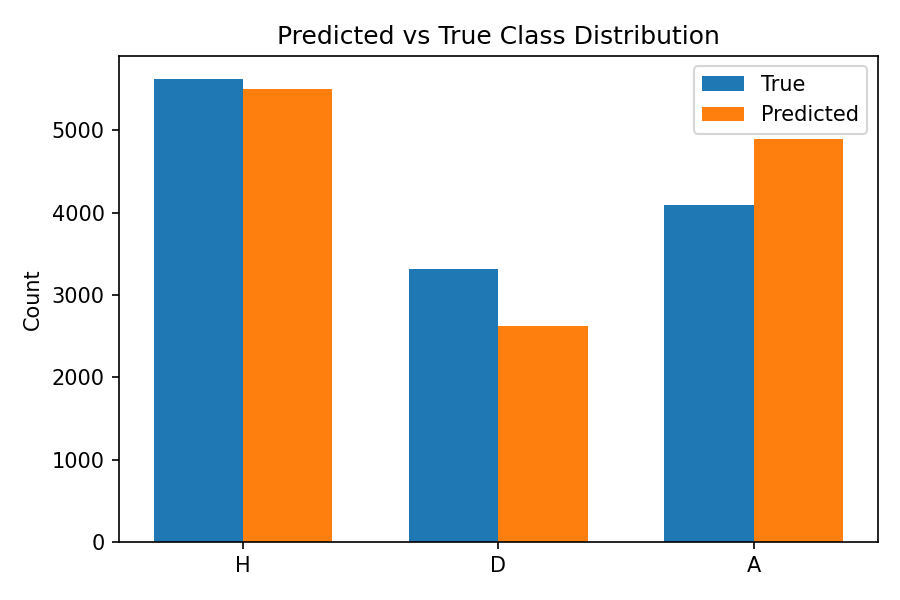

### confusion_matrix.png

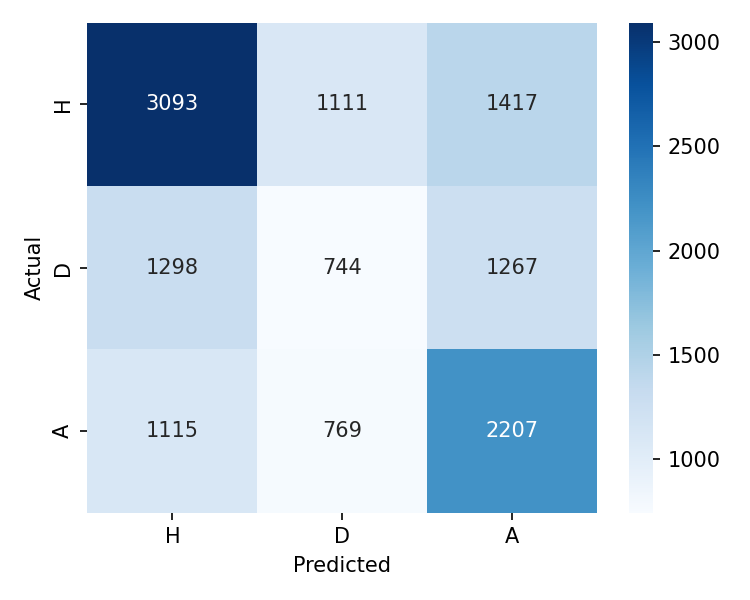

**Training divergence:** `/reports/training_divergence_8b98b3dc83524ea8b52da5faed1f8de8`

## `training_divergence_8b98b3dc83524ea8b52da5faed1f8de8`

# Training Divergence Report

- Run id: 8b98b3dc83524ea8b52da5faed1f8de8
- Model: main_xgboost
- Created: 2026-02-07T01:19:21.354536+00:00
- League: all
- Season: all

## First Divergence Point
- loss_increase_step: None
- nan_inf_steps: []
- output_saturated: False

## Overfit Diagnostics
- best_step: 15
- first_overfit_step: None
- final_minus_best: 0.0

## Diagnosis
- Feature ranges vary widely (p01-p99 span ratio > 100). Trees don't require scaling, but huge ranges often mean unit/outlier bugs.
- Detected 8 features with extreme outliers.

## Files
- step_metrics.csv: /reports/training_divergence_8b98b3dc83524ea8b52da5faed1f8de8/step_metrics.csv
- feature_scaling.csv: /reports/training_divergence_8b98b3dc83524ea8b52da5faed1f8de8/feature_scaling.csv
- divergence_summary.csv: /reports/training_divergence_8b98b3dc83524ea8b52da5faed1f8de8/divergence_summary.csv
- loss_lr.png: /reports/training_divergence_8b98b3dc83524ea8b52da5faed1f8de8/loss_lr.png
- grad_norm.png: N/A

### feature_scaling.csv

,feature,median,p01,p99,q25,q75,iqr,min,max,missing_pct,outlier_flag
0,home_points_last_5,6.0,0.0,15.0,4.0,9.0,5.0,0.0,15.0,0.000000,False
1,home_points_last_10,11.0,0.0,25.0,7.0,16.0,9.0,0.0,30.0,0.000000,False
2,away_points_last_5,6.0,0.0,15.0,4.0,9.0,5.0,0.0,15.0,0.000000,False
3,away_points_last_10,12.0,0.0,26.0,7.0,16.0,9.0,0.0,30.0,0.000000,False
4,home_wins_last_5,2.0,0.0,5.0,1.0,2.0,1.0,0.0,5.0,0.000000,False
5,home_draws_last_5,1.0,0.0,4.0,0.0,2.0,2.0,0.0,5.0,0.000000,False
6,home_losses_last_5,2.0,0.0,4.0,1.0,2.0,1.0,0.0,5.0,0.000000,False
7,away_wins_last_5,2.0,0.0,5.0,1.0,2.0,1.0,0.0,5.0,0.000000,False
8,away_draws_last_5,1.0,0.0,4.0,0.0,2.0,2.0,0.0,5.0,0.000000,False
9,away_losses_last_5,2.0,0.0,4.0,1.0,2.0,1.0,0.0,5.0,0.000000,False


### step_metrics.csv

,step,train_logloss,val_logloss,learning_rate
0,1,1.095512,1.095052,0.05
1,2,1.092670,1.091902,0.05
2,3,1.089955,1.088887,0.05
3,4,1.087398,1.086084,0.05
4,5,1.085028,1.083515,0.05
5,6,1.082795,1.081158,0.05
6,7,1.080612,1.078799,0.05
7,8,1.078574,1.076685,0.05
8,9,1.076713,1.074777,0.05
9,10,1.074917,1.072956,0.05


### divergence_summary.csv

,reason,step,batch,loss,accuracy,learning_rate
0,best_step,15,NaN,1.065565,NaN,0.05
1,final_minus_best,final,NaN,0.000000,NaN,NaN


### loss_lr.png

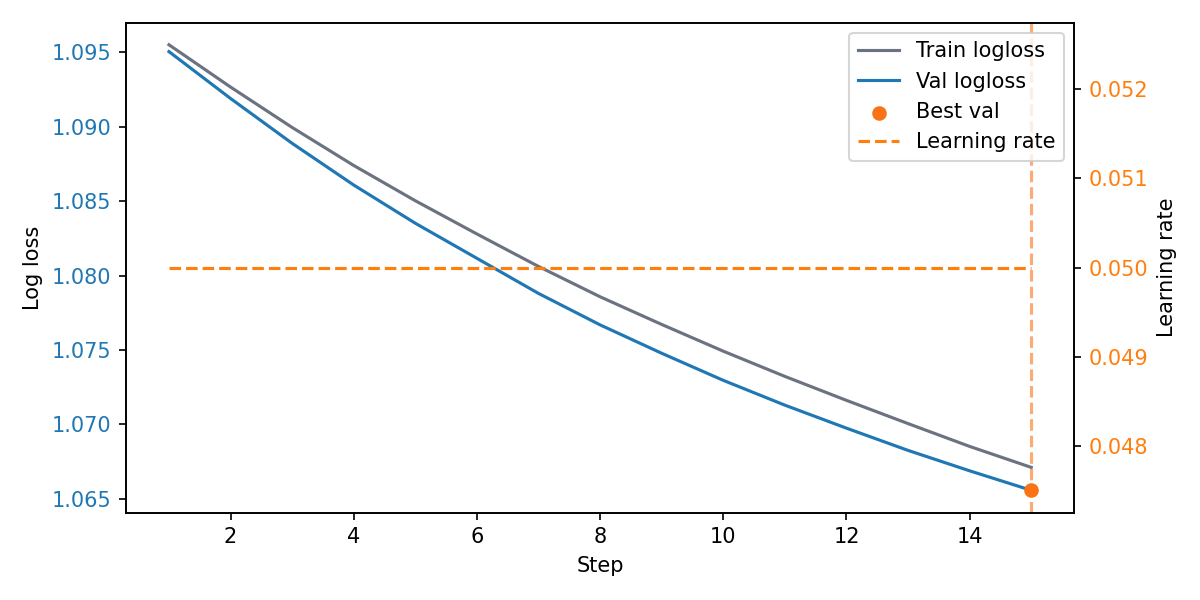

In [5]:
from pathlib import Path
import pandas as pd

from IPython.display import display, Markdown, Image

# In your compose you mount: ./reports:/reports
REPORTS = Path("/reports")

def latest_dir_contains(token: str) -> Path | None:
    if not REPORTS.exists():
        display(Markdown(f"❌ REPORTS path does not exist: `{REPORTS}`"))
        return None

    dirs = [p for p in REPORTS.iterdir() if p.is_dir() and token in p.name]
    if not dirs:
        return None

    return sorted(dirs, key=lambda p: p.stat().st_mtime, reverse=True)[0]

def show_report_dir(d: Path | None, max_rows: int = 40):
    if d is None or not d.exists():
        display(Markdown("**No report directory found.**"))
        return

    display(Markdown(f"## `{d.name}`"))

    md = next(iter(d.glob("*.md")), None)
    if md:
        display(Markdown(md.read_text(encoding="utf-8", errors="ignore")))

    for name in [
        "class_counts.csv",
        "confusion_matrix.csv",
        "feature_scaling.csv",
        "step_metrics.csv",
        "divergence_summary.csv",
    ]:
        fp = d / name
        if fp.exists():
            display(Markdown(f"### {name}"))
            df = pd.read_csv(fp)
            display(df.head(max_rows))

    for name in [
        "predicted_vs_true.png",
        "confusion_matrix.png",
        "loss_lr.png",
        "grad_norm.png",
    ]:
        fp = d / name
        if fp.exists():
            display(Markdown(f"### {name}"))
            display(Image(filename=str(fp)))

def preview_latest_reports():
    display(Markdown("# Latest reports"))

    di = latest_dir_contains("dataset_integrity")
    la = latest_dir_contains("label_audit")
    td = latest_dir_contains("training_divergence")

    display(Markdown(f"**Dataset integrity:** `{di}`" if di else "**Dataset integrity:** *(none found)*"))
    if di: show_report_dir(di)

    display(Markdown(f"**Label audit:** `{la}`" if la else "**Label audit:** *(none found)*"))
    if la: show_report_dir(la)

    display(Markdown(f"**Training divergence:** `{td}`" if td else "**Training divergence:** *(none found)*"))
    if td: show_report_dir(td)

# ✅ THIS is what makes it actually show something:
preview_latest_reports()
